# Visualiser le prétraitement `matched_resolution`

Comparaison RAW / T50kpcSUB / CHANDRA pour un amas choisi : FITS natifs, grille physique commune, couvertures et entrées normalisées du modèle.

Le notebook réutilise `ClusterDataset` et son cache physique. Aucun entraînement, aucune estimation de normalisation : les bornes sont celles du **train du fold choisi**, sauvegardées dans les configurations. Les augmentations sont désactivées. Par défaut, seuls les amas du train sont proposés pour éviter d'inspecter le test externe pendant le développement.

Les images natives sont affichées sur leurs propres WCS et avec un contraste par image. Elles ne sont donc pas directement comparables pixel à pixel. Les images harmonisées partagent leur WCS ; les deux radios partagent aussi leur beam et l'échelle de couleur. CHANDRA est reprojeté, **sans convolution au beam radio**.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, AsinhNorm
from IPython.display import display

PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "clusterprep/src/clusterprep").is_dir()), None)
if PROJECT is None:
    raise RuntimeError("Ouvrir ce notebook depuis le projet PH_Project_I")
sys.path.insert(0, str(PROJECT / "clusterprep/src"))
from clusterprep.dataset import ClusterDataset
from clusterprep.io import load_celestial_fits

MANIFEST = PROJECT / "clusterprep/configs/phase7b_multimodal/cohort_manifest.json"
RUNS_ROOT = PROJECT / "outputs/phase7b_multimodal_cli"
FOLD = 0
SPLIT = "train"  # train, validation, test (inspection explicite du test réservé)
CLUSTER_ID = None  # ex. "PSZ2G023.17+86.71" ; None = premier amas de la sélection
CHANDRA_FILTER = "present"  # present, absent, all
EXPORT_FIGURES = False
EXPORT_DIR = PROJECT / "outputs/matched_preprocessing_visualization"
# Facultatif : chemins exacts des runs si plusieurs entraînements existent pour un fold.
RUN_DIRS = {}  # {"RAW": Path(...), "T50kpcSUB": Path(...)}


## Choix de l’amas et des paramètres sauvegardés

Modifier `FOLD`, `CLUSTER_ID` ou `CHANDRA_FILTER`, puis réexécuter les cellules suivantes. Avec `CHANDRA_FILTER = "absent"`, l'image et le masque X-ray transmis au modèle doivent être entièrement nuls. Une observation présente mais non couverte reste distinguée d'une observation absente.

In [2]:
manifest = json.loads(MANIFEST.read_text())
info = manifest["samples"]
configs, splits, run_dirs = {}, {}, {}
for product in ("RAW", "T50kpcSUB"):
    if product in RUN_DIRS:
        directory = Path(RUN_DIRS[product])
    else:
        candidates = sorted((RUNS_ROOT / product / f"fold_{FOLD}").glob("*/config.json"))
        candidates = [p for p in candidates if (p.parent / "status.json").exists()
                      and json.loads((p.parent / "status.json").read_text()).get("status") == "completed"]
        if len(candidates) != 1:
            raise ValueError(f"{product}: {len(candidates)} runs ; renseigner RUN_DIRS explicitement")
        directory = candidates[0].parent
    run_dirs[product] = directory
    configs[product] = json.loads((directory / "config.json").read_text())["config"]
    splits[product] = json.loads((directory / "splits.json").read_text())
    assert configs[product]["radio_preprocessing"] == "matched_resolution"
    norm = json.loads((directory / "normalization.json").read_text())
    assert set(norm["train_keys"]) == set(splits[product]["train"])
    assert norm["bounds"] == configs[product]["normalization_bounds"]
    for modality in ("radio", "xray"):
        assert configs[product]["normalization"][modality]["scope"] == "train"

split_field = "reserved_external_test" if SPLIT == "test" else SPLIT
assert SPLIT in ("train", "validation", "test")
assert CHANDRA_FILTER in ("present", "absent", "all")
keys = splits["RAW"][split_field]
assert set(keys) == set(splits["T50kpcSUB"][split_field])
choices = [k for k in keys if CHANDRA_FILTER == "all"
           or bool(info[k].get("chandra_path")) == (CHANDRA_FILTER == "present")]
if not choices:
    raise ValueError("Aucun amas pour cette sélection")
key = choices[0] if CLUSTER_ID is None else next(
    (k for k in choices if info[k]["cluster_id"] == CLUSTER_ID), None)
if key is None:
    raise ValueError("CLUSTER_ID absent du split ou du filtre choisi")
display(pd.DataFrame([{"cluster_id": info[k]["cluster_id"],
                       "CHANDRA présent": bool(info[k].get("chandra_path"))} for k in choices]))
print("Amas sélectionné :", info[key]["cluster_id"], "— split :", SPLIT)


,cluster_id,CHANDRA présent
0,PSZ2G023.17+86.71,True
1,PSZ2G031.93+78.71,True
2,PSZ2G040.58+77.12,True
3,PSZ2G046.88+56.48,True
4,PSZ2G049.18+65.05,True
5,PSZ2G049.32+44.37,True
6,PSZ2G050.46+67.54,True
7,PSZ2G055.59+31.85,True
8,PSZ2G057.78+52.32,True
9,PSZ2G057.92+27.64,True


Amas sélectionné : PSZ2G023.17+86.71 — split : train


In [3]:
datasets, samples = {}, {}
for product, cfg in configs.items():
    datasets[product] = ClusterDataset(
        info, [key], ["RR", "RH"], mode="multimodal", task="rr_rh",
        candidate_policy=cfg["candidate_policy"], size=cfg["size"],
        modalities=["radio", "xray"], include_masks=True,
        missing_modality_policy="optional", radio_source=product,
        radio_preprocessing="matched_resolution",
        matched_resolution=cfg["matched_resolution"], matched_records=cfg.get("matched_records"),
        matched_cache_dir=cfg.get("matched_cache_dir") or manifest["cache_root"],
        normalization=cfg["normalization"], normalization_bounds=cfg["normalization_bounds"],
        augment=False, training=False, cache=True)
    samples[product] = datasets[product][0]

# Accès au même store que ClusterDataset pour montrer les masques spécifiques
# avant l'application éventuelle de l'intersection radio.
adapter = datasets["RAW"]._matched
selected_info = datasets["RAW"].data_info[key]
pair, cache_info = adapter.store.get(
    adapter.sources(selected_info), adapter.record(selected_info),
    datasets["RAW"].size, adapter.options.preprocessing_parameters())
sources = adapter.sources(selected_info)
native = {name: load_celestial_fits(path) if path else None for name, path in sources.items()}
print("Cache :", cache_info)
display(pd.DataFrame([pair.metadata["coverage"]], index=["Fraction de couverture"]))
display(pd.DataFrame([pair.metadata["target_resolution"]]).drop(columns=["cosmology"], errors="ignore"))
print("CHANDRA :", pair.metadata["chandra_status"])
display(pd.DataFrame({p: {"normalisation": cfg["normalization"],
                         "bornes train figées": cfg["normalization_bounds"],
                         "masque radio": cfg["matched_resolution"].get("radio_mask", "intersection")}
                      for p, cfg in configs.items()}))


Cache : {'key': 'f5ac4011696b858b09448df1d9b02f81eb8f50dd4bb532edc8463f838d21249d', 'path': '/Users/antoinegdrn/PH_Project_I/outputs/optional_chandra_phase6/cache/matched_resolution/v1/PSZ2G023.17+86.71/f5ac4011696b858b09448df1d9b02f81eb8f50dd4bb532edc8463f838d21249d.npz', 'status': 'memory'}


  'degree' -> 'deg',
  'degree' -> 'deg'. [astropy.wcs.wcs]


,CHANDRA,RAW,T50kpcSUB,intersection
Fraction de couverture,0.621643,1.0,1.0,1.0


,fwhm_arcsec,fwhm_kpc,fwhm_over_r500,r500_kpc
0,22.907445,106.752159,0.097669,1093.0


CHANDRA : present_covered


,RAW,T50kpcSUB
normalisation,"{'radio': {'scope': 'train', 'method': 'asinh_...","{'radio': {'scope': 'train', 'method': 'asinh_..."
bornes train figées,"{'radio': [[-8.330721029778943e-05, 0.00751905...","{'radio': [[-7.161376415751875e-05, 0.00144183..."
masque radio,intersection,intersection


## FITS natifs → grille harmonisée → masques → entrées du modèle

Les pixels invalides sont gris. Les percentiles utilisés pour le **contraste des figures** ne modifient ni les images ni la normalisation du dataset. La dernière ligne représente les tenseurs exacts du dataset, sans augmentation ; les valeurs hors masque y sont nulles. Les unités natives radio peuvent différer des unités physiques de sortie : ne pas interpréter le changement de contraste comme une variation de flux.

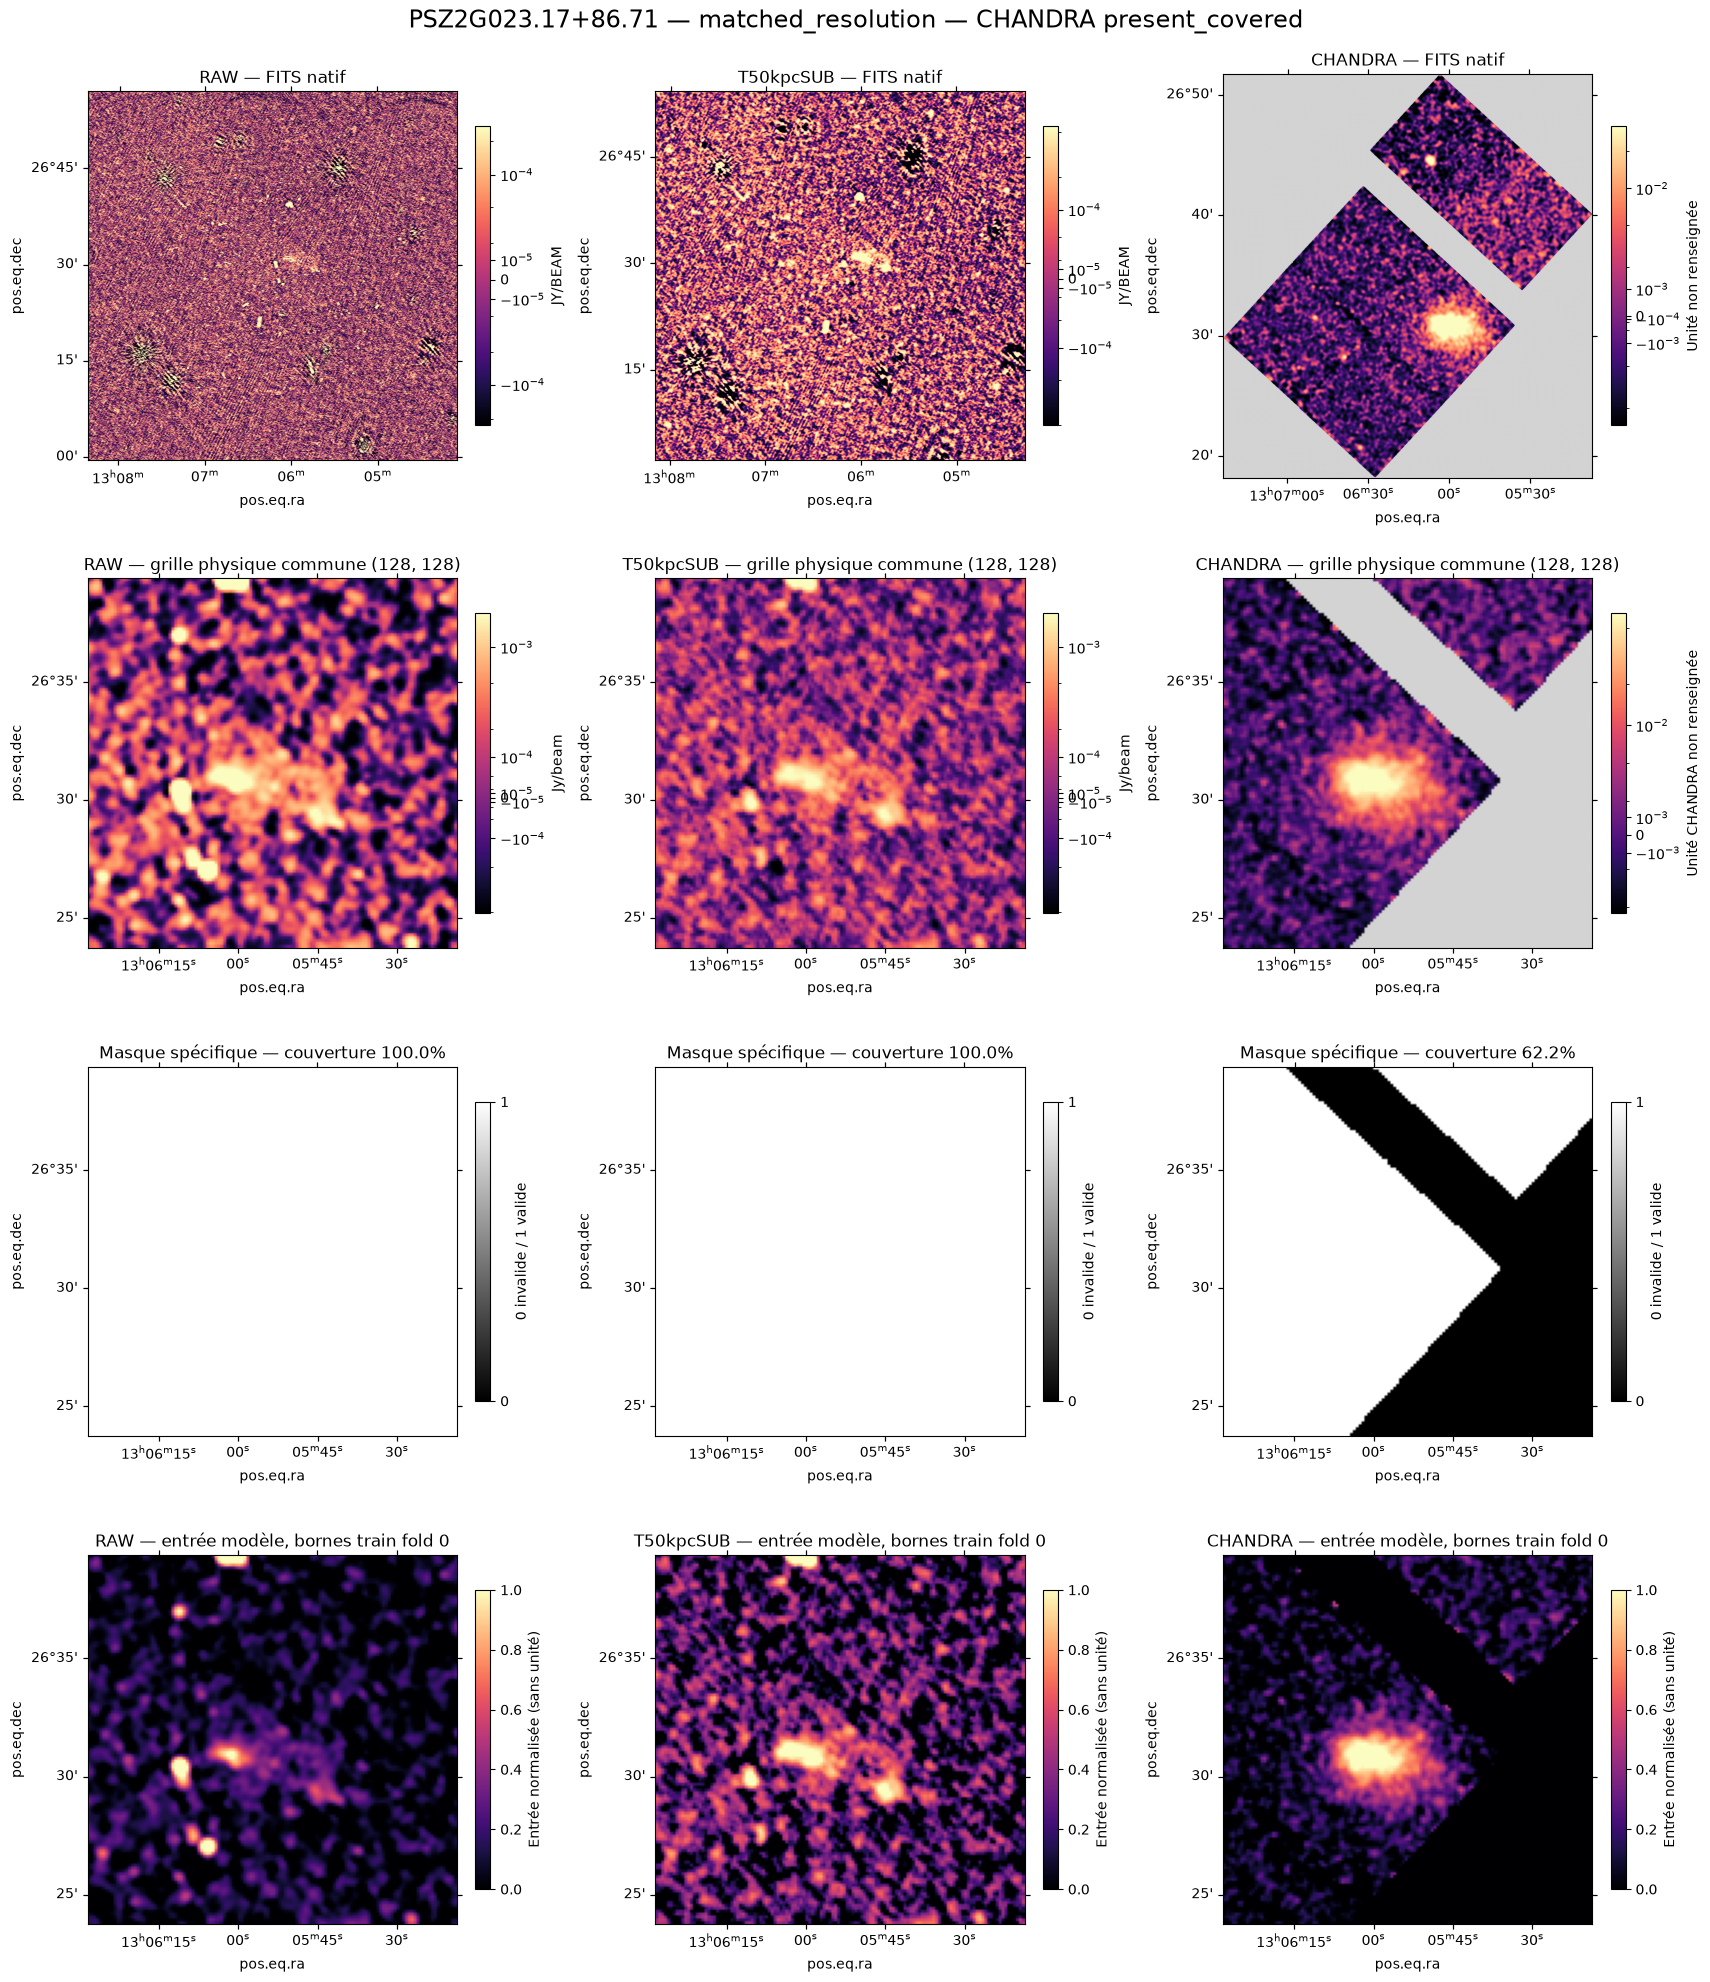

In [4]:
def contrast(values):
    values = np.asarray(values)
    values = values[np.isfinite(values)]
    if not values.size:
        return Normalize(0, 1)
    lo, hi = np.percentile(values, [1, 99])
    if hi <= lo:
        hi = lo + max(abs(lo) * 0.01, 1e-8)
    return AsinhNorm(linear_width=max((hi-lo)/20, 1e-12), vmin=lo, vmax=hi)

cmap = plt.get_cmap("magma").copy()
cmap.set_bad("lightgray")
products = ["RAW", "T50kpcSUB", "CHANDRA"]
images = [pair.raw, pair.t50kcpsub, pair.chandra]
masks = [pair.raw_mask, pair.t50kcpsub_mask, pair.chandra_mask]
radio_norm = contrast(np.concatenate([pair.raw[pair.raw_mask], pair.t50kcpsub[pair.t50kcpsub_mask]]))
fig = plt.figure(figsize=(17, 20), layout="constrained")
for col, name in enumerate(products):
    plane = native[name]
    ax = fig.add_subplot(4, 3, col+1, projection=plane[2] if plane else None)
    if plane is None:
        ax.text(.5, .5, "CHANDRA absent : aucun FITS", ha="center", va="center", transform=ax.transAxes)
    else:
        data, header, wcs = plane
        im = ax.imshow(np.ma.masked_invalid(data), origin="lower", cmap=cmap, norm=contrast(data))
        fig.colorbar(im, ax=ax, shrink=.7, label=header.get("BUNIT", "Unité non renseignée"))
    ax.set_title(f"{name} — FITS natif")
    ax = fig.add_subplot(4, 3, col+4, projection=pair.wcs)
    im = ax.imshow(np.ma.masked_where(~masks[col], images[col]), origin="lower", cmap=cmap,
                   norm=radio_norm if col < 2 else contrast(images[col][masks[col]]))
    unit = pair.metadata["bunit"] if col < 2 else (pair.metadata.get("chandra_bunit") or "Unité CHANDRA non renseignée")
    fig.colorbar(im, ax=ax, shrink=.7, label=unit)
    ax.set_title(f"{name} — grille physique commune {images[col].shape}")
    ax = fig.add_subplot(4, 3, col+7, projection=pair.wcs)
    im = ax.imshow(masks[col], origin="lower", cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Masque spécifique — couverture {masks[col].mean():.1%}")
    fig.colorbar(im, ax=ax, shrink=.7, ticks=[0, 1], label="0 invalide / 1 valide")
    sample = samples[name] if col < 2 else samples["RAW"]
    field = "raw" if col < 2 else "chandra"
    ax = fig.add_subplot(4, 3, col+10, projection=pair.wcs)
    im = ax.imshow(sample[field][0].numpy(), origin="lower", cmap=cmap, vmin=0, vmax=1)
    fig.colorbar(im, ax=ax, shrink=.7, label="Entrée normalisée (sans unité)")
    ax.set_title(f"{name} — entrée modèle, bornes train fold {FOLD}")
fig.suptitle(f"{info[key]['cluster_id']} — matched_resolution — CHANDRA {pair.metadata['chandra_status']}", fontsize=17)
plt.show()
if EXPORT_FIGURES:
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(EXPORT_DIR / f"{info[key]['cluster_id']}_fold{FOLD}_preprocessing.png", dpi=150)


## Masque commun et contrôles d’alignement

Le masque commun est l'intersection des deux couvertures radio. Il peut être plus petit que les masques spécifiques affichés ci-dessus. Les masques effectivement utilisés par le dataset sont montrés ici. Un contour cyan indique la couverture CHANDRA, lorsqu'elle est partielle. Les assertions contrôlent les tenseurs réellement retournés, y compris CHANDRA absent.

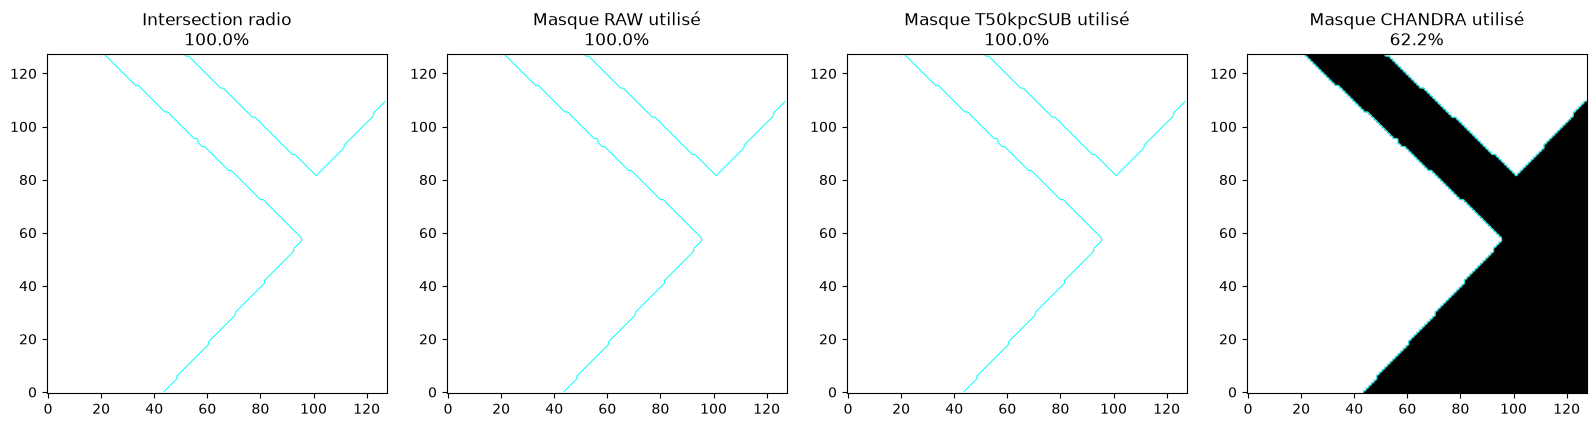

Contrôles réussis : dimensions, masques, CHANDRA partagé, labels et valeurs hors couverture.


In [5]:
fig_masks, axes = plt.subplots(1, 4, figsize=(16, 4), layout="constrained")
for ax, title, mask in zip(axes,
        ["Intersection radio", "Masque RAW utilisé", "Masque T50kpcSUB utilisé", "Masque CHANDRA utilisé"],
        [pair.common_radio_mask, samples["RAW"]["raw_mask"][0].numpy(),
         samples["T50kpcSUB"]["raw_mask"][0].numpy(), samples["RAW"]["chandra_mask"][0].numpy()]):
    ax.imshow(mask, origin="lower", cmap="gray", vmin=0, vmax=1)
    if pair.chandra_mask.any() and not pair.chandra_mask.all():
        ax.contour(pair.chandra_mask.astype(float), levels=[.5], colors="cyan", linewidths=.7)
    ax.set_title(f"{title}\n{np.mean(mask):.1%}")
plt.show()
for product, sample in samples.items():
    assert sample["cluster_id"] == info[key]["cluster_id"]
    assert sample["raw"].shape == sample["chandra"].shape == (1, configs[product]["size"], configs[product]["size"])
    for field in ("raw", "chandra"):
        array, mask = sample[field].numpy(), sample[field+"_mask"].numpy()
        assert np.isfinite(array).all()
        assert np.all(array[mask == 0] == 0)
    if configs[product]["matched_resolution"].get("radio_mask", "intersection") == "intersection":
        np.testing.assert_array_equal(sample["raw_mask"][0].numpy(), pair.common_radio_mask)
np.testing.assert_array_equal(samples["RAW"]["chandra"], samples["T50kpcSUB"]["chandra"])
np.testing.assert_array_equal(samples["RAW"]["chandra_mask"], samples["T50kpcSUB"]["chandra_mask"])
for field in ("label", "label_mask"):
    np.testing.assert_array_equal(samples["RAW"][field], samples["T50kpcSUB"][field])
if not sources["CHANDRA"]:
    assert not samples["RAW"]["chandra"].any()
    assert not samples["RAW"]["chandra_mask"].any()
print("Contrôles réussis : dimensions, masques, CHANDRA partagé, labels et valeurs hors couverture.")
if EXPORT_FIGURES:
    fig_masks.savefig(EXPORT_DIR / f"{info[key]['cluster_id']}_fold{FOLD}_masks.png", dpi=150)
